# Bank Marketing: логистическая регрессия

Первый учебный эксперимент по бинарной классификации. Цель — пройти путь от
таблицы данных до проверки модели и прогноза для одного клиента.

**Задача:** оценить вероятность оформления срочного депозита до звонка клиенту.
Ответ `yes` кодируется как `1`, `no` — как `0`.

Используется `bank-full.csv` из [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing).
Пояснения к данным и атрибуция приведены в [DATASET.md](DATASET.md), запуск — в [README.md](README.md).

План: данные → train/validation/test → подготовка признаков → обучение → baseline
и метрики → итоговое обучение → test → отдельный прогноз.

## 1. Окружение и настройки

Запускай notebook из корня репозитория после установки `requirements.txt`.
Разбиение, признаки, настройки модели и порог зафиксированы. Перебора моделей
или настройки по test здесь нет.

In [1]:
from pathlib import Path
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, log_loss
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
THRESHOLD = 0.5
DATA_PATH = Path('bank-full.csv')

numerical = ['age', 'balance', 'previous']
categorical = ['job', 'education', 'housing', 'loan', 'poutcome']
features = categorical + numerical

print(f'Python: {platform.python_version()}')
print(f'NumPy: {np.__version__}; pandas: {pd.__version__}; scikit-learn: {sklearn.__version__}')

Python: 3.12.14
NumPy: 2.3.5; pandas: 2.2.3; scikit-learn: 1.8.0


## 2. Данные и выбранные признаки

`bank-full.csv` содержит 45 211 строк. Это конкретная версия набора UCI;
`bank-additional-full.csv` имеет другой состав признаков и в этом проекте не используется.

Числа: возраст (`age`), среднегодовой баланс в евро (`balance`) и количество
контактов до текущей кампании (`previous`). Категории описывают профессию,
образование, наличие жилищного и потребительского кредитов, исход предыдущей кампании.

`duration` исключён: длительность звонка неизвестна в момент прогноза до звонка.
Строка `unknown` сохраняется как отдельная категория и не является `NaN`.

In [2]:
df = pd.read_csv(DATA_PATH, sep=';')

required_columns = features + ['y']
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f'Missing columns: {missing_columns}. Use bank-full.csv from UCI bank.zip.')
if set(df['y'].dropna().unique()) != {'yes', 'no'} or df['y'].isna().any():
    raise ValueError('Expected target y to contain only yes and no, without missing values.')
if df[features].isna().any().any():
    raise ValueError('Selected features contain missing values; inspect the input data first.')

print(f'Rows: {len(df):,}; original columns: {df.shape[1]}; selected features: {len(features)}')
display(df[required_columns].head(3))
display(pd.DataFrame({
    'dtype': df[required_columns].dtypes.astype(str),
    'missing': df[required_columns].isna().sum(),
}))

Rows: 45,211; original columns: 17; selected features: 8


,job,education,housing,loan,poutcome,age,balance,previous,y
0,management,tertiary,yes,no,unknown,58,2143,0,no
1,technician,secondary,yes,no,unknown,44,29,0,no
2,entrepreneur,secondary,yes,yes,unknown,33,2,0,no


,dtype,missing
job,object,0
education,object,0
housing,object,0
loan,object,0
poutcome,object,0
age,int64,0
balance,int64,0
previous,int64,0
y,object,0


## 3. Разбиение 60/20/20

Train служит для обучения, validation — для проверки реализации и сравнения
с baseline, test — для итоговой оценки зафиксированного решения.

Оба разбиения стратифицированы по ответу. После выделения 20% на test четверть
от оставшихся 80% даёт 20% исходного набора для validation.

Исходный `df['y']` остаётся строковым: повторный запуск ячейки не уничтожает ответы.

In [3]:
df_features = df[features].copy()
y = df['y'].map({'yes': 1, 'no': 0})

df_train, df_test, y_train, y_test = train_test_split(
    df_features, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y,
)
df_train, df_val, y_train, y_val = train_test_split(
    df_train, y_train, test_size=0.25, random_state=RANDOM_STATE, stratify=y_train,
)

assert df_train.index.equals(y_train.index)
assert df_val.index.equals(y_val.index)
assert df_test.index.equals(y_test.index)
assert set(df_train.index).isdisjoint(df_val.index)
assert set(df_train.index).isdisjoint(df_test.index)
assert set(df_val.index).isdisjoint(df_test.index)
assert len(df_train) + len(df_val) + len(df_test) == len(df)
assert 'y' not in features and 'duration' not in features

split_summary = pd.DataFrame([
    {'split': name, 'rows': len(target), 'positive_count': int(target.sum()),
     'positive_share': target.mean()}
    for name, target in [('train', y_train), ('validation', y_val), ('test', y_test)]
]).set_index('split')
display(split_summary.round(6))

,rows,positive_count,positive_share
split,,,
train,27126,3173,0.116973
validation,9042,1058,0.117010
test,9043,1058,0.116997


## 4. Краткая проверка train

Категории и их частоты смотрим на обучающей части. На этапе подготовки
словарь категорий и параметры масштабирования будут вычислены только по train.

In [4]:
display(df_train[numerical].describe().round(2))
category_summary = pd.DataFrame({
    'unique_categories': df_train[categorical].nunique(),
    'unknown_count': df_train[categorical].eq('unknown').sum(),
})
display(category_summary)
print('Training positive share:', round(float(y_train.mean()), 6))

Training positive share: 0.116973


,age,balance,previous
count,27126.00,27126.00,27126.00
mean,40.89,1368.13,0.58
std,10.63,3087.75,1.97
min,18.00,-6847.00,0.00
25%,33.00,73.00,0.00
50%,39.00,454.00,0.00
75%,48.00,1425.75,0.00
max,95.00,81204.00,58.00


,unique_categories,unknown_count
job,12,179
education,4,1100
housing,2,0
loan,2,0
poutcome,4,22240


## 5. Подготовка признаков

`DictVectorizer` превращает строковые категории в индикаторы `0/1`, а числа
сохраняет числовыми. Названия столбцов берём у обученного векторизатора.

Для трёх числовых столбцов `StandardScaler` вычисляет:

$$
z_j = \frac{x_j - \mu_{j,\mathrm{train}}}{s_{j,\mathrm{train}}}.
$$

Это приводит числовые признаки к сопоставимому масштабу, влияет на условия
оптимизации и действие регуляризации. Категориальные индикаторы оставляем `0/1`.
Validation преобразуется теми же обученными объектами через `transform`.

In [5]:
train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train_encoded = dv.fit_transform(train_dicts)
X_val_encoded = dv.transform(val_dicts)

feature_names = dv.get_feature_names_out()
numerical_mask = np.isin(feature_names, numerical)

scaler = StandardScaler()
X_train_scaled = X_train_encoded.copy()
X_val_scaled = X_val_encoded.copy()
X_train_scaled[:, numerical_mask] = scaler.fit_transform(X_train_encoded[:, numerical_mask])
X_val_scaled[:, numerical_mask] = scaler.transform(X_val_encoded[:, numerical_mask])

assert numerical_mask.sum() == len(numerical)
assert X_train_scaled.shape[1] == X_val_scaled.shape[1]
assert np.isfinite(X_train_scaled).all() and np.isfinite(X_val_scaled).all()
assert np.allclose(X_train_scaled[:, numerical_mask].mean(axis=0), 0, atol=1e-10)
assert np.allclose(X_train_scaled[:, numerical_mask].std(axis=0), 1)
assert np.array_equal(X_train_scaled[:, ~numerical_mask], X_train_encoded[:, ~numerical_mask])

print('Train:', X_train_scaled.shape, 'Validation:', X_val_scaled.shape)

Train: (27126, 27) Validation: (9042, 27)


## 6. Логистическая регрессия

Модель выдаёт оценку вероятности согласия:

$$
p_i = \sigma(w_0 + x_i^T w), \qquad \sigma(t) = \frac{1}{1+e^{-t}}.
$$

Решение получаем отдельно: при `p >= 0.5` выбираем `1`, иначе `0`.
Сохраняем исходные настройки: `solver='lbfgs'`, `C=1.0`, `max_iter=100`.

In [6]:
model = LogisticRegression(solver='lbfgs', C=1.0, max_iter=100)
model.fit(X_train_scaled, y_train)
assert model.classes_.tolist() == [0, 1]

val_probabilities = model.predict_proba(X_val_scaled)[:, 1]
val_decisions = val_probabilities >= THRESHOLD
print('Optimization iterations:', model.n_iter_[0])

Optimization iterations: 28


## 7. Baseline и оценка на validation

Baseline назначает каждому клиенту одну вероятность — долю согласий на train:

$$
p_{\mathrm{baseline}} = \operatorname{mean}(y_{\mathrm{train}}).
$$

Здесь она около 11,7%. После порога `0.5` все решения baseline равны `0`.
Большинство клиентов отказываются, поэтому такой прогноз получает около 88,3%
accuracy, хотя не находит ни одного согласившегося.

**Accuracy** — доля верных решений; больше — лучше:

$$
\mathrm{Accuracy} = \frac{1}{n}\sum_i \mathbf{1}(\hat y_i = y_i).
$$

**Log loss** оценивает вероятности; меньше — лучше:

$$
\mathrm{LogLoss} = -\frac{1}{n}\sum_i
\left[y_i\ln p_i + (1-y_i)\ln(1-p_i)\right].
$$

Log loss применим и к постоянным вероятностям baseline. Он показывает,
улучшает ли модель вероятностные прогнозы относительно общего прогноза для всех.
В `accuracy_score` передаём решения после порога, в `log_loss` — вероятности до порога.

In [7]:
val_baseline_probability = float(y_train.mean())
val_baseline_probabilities = np.full(len(y_val), val_baseline_probability)
val_baseline_decisions = val_baseline_probabilities >= THRESHOLD

validation_results = pd.DataFrame([
    {
        'method': 'Baseline',
        'accuracy': accuracy_score(y_val, val_baseline_decisions),
        'log_loss': log_loss(y_val, val_baseline_probabilities),
    },
    {
        'method': 'Logistic regression',
        'accuracy': accuracy_score(y_val, val_decisions),
        'log_loss': log_loss(y_val, val_probabilities),
    },
]).set_index('method')
display(validation_results.round(6))

,accuracy,log_loss
method,,
Baseline,0.882990,0.360924
Logistic regression,0.894382,0.316309


Модель лучше baseline на validation по обеим выбранным метрикам.
Признаки, настройки и порог зафиксированы. Следующий этап использует train + validation
для обучения новой итоговой модели и test для оценки.

Этот notebook оформлен после исходного учебного эксперимента: его test-результаты
уже известны. При оформлении новые признаки и настройки по test не подбирались.

## 8. Итоговое обучение на train + validation

Объединяем исходные таблицы и ответы. Векторизатор, scaler и модель создаются
заново. Суффикс `_final` отделяет их от объектов предыдущего этапа.

In [8]:
df_full_train = pd.concat([df_train, df_val])
y_full_train = pd.concat([y_train, y_val])
assert df_full_train.index.equals(y_full_train.index)
assert set(df_full_train.index).isdisjoint(df_test.index)
print('Full train:', len(df_full_train), 'Test:', len(df_test))

dv_final = DictVectorizer(sparse=False)
X_full_train_encoded = dv_final.fit_transform(df_full_train.to_dict(orient='records'))
X_test_encoded = dv_final.transform(df_test.to_dict(orient='records'))

feature_names_final = dv_final.get_feature_names_out()
numerical_mask_final = np.isin(feature_names_final, numerical)

scaler_final = StandardScaler()
X_full_train_scaled = X_full_train_encoded.copy()
X_test_scaled = X_test_encoded.copy()
X_full_train_scaled[:, numerical_mask_final] = scaler_final.fit_transform(
    X_full_train_encoded[:, numerical_mask_final]
)
X_test_scaled[:, numerical_mask_final] = scaler_final.transform(
    X_test_encoded[:, numerical_mask_final]
)

assert numerical_mask_final.sum() == len(numerical)
assert np.isfinite(X_full_train_scaled).all() and np.isfinite(X_test_scaled).all()
assert np.array_equal(X_test_scaled[:, ~numerical_mask_final], X_test_encoded[:, ~numerical_mask_final])

model_final = LogisticRegression(solver='lbfgs', C=1.0, max_iter=100)
model_final.fit(X_full_train_scaled, y_full_train)
assert model_final.classes_.tolist() == [0, 1]
print('Optimization iterations:', model_final.n_iter_[0])

Full train: 36168 Test: 9043
Optimization iterations: 25


## 9. Результаты на test

Для test используем только `transform` и `predict_proba` итоговых объектов.
Вероятность итогового baseline вычисляем по `y_full_train`, а не по ответам test.
Порог сохраняется равным `0.5`.

In [9]:
test_probabilities = model_final.predict_proba(X_test_scaled)[:, 1]
test_decisions = test_probabilities >= THRESHOLD

test_baseline_probability = float(y_full_train.mean())
test_baseline_probabilities = np.full(len(y_test), test_baseline_probability)
test_baseline_decisions = test_baseline_probabilities >= THRESHOLD

test_results = pd.DataFrame([
    {
        'method': 'Baseline',
        'accuracy': accuracy_score(y_test, test_baseline_decisions),
        'log_loss': log_loss(y_test, test_baseline_probabilities),
    },
    {
        'method': 'Logistic regression',
        'accuracy': accuracy_score(y_test, test_decisions),
        'log_loss': log_loss(y_test, test_probabilities),
    },
]).set_index('method')
display(test_results.round(6))

results = pd.concat({'validation': validation_results, 'test': test_results}, names=['split'])
display(results.round(6))

,accuracy,log_loss
method,,
Baseline,0.883003,0.360898
Logistic regression,0.893066,0.316915


accuracy  log_loss
split      method                                 
validation Baseline             0.882990  0.360924
           Logistic regression  0.894382  0.316309
test       Baseline             0.883003  0.360898
           Logistic regression  0.893066  0.316915

## 10. Какие ошибки остаются

Матрица ошибок показывает количество клиентов для каждого сочетания факта и
решения. Строки — фактический ответ, столбцы — прогноз. Диагональ содержит верные решения.

Дополнительно посчитаем долю найденных согласий среди всех фактических согласий
(recall класса `1`). Это описательная проверка зафиксированной модели, без изменения порога.

Found positive clients: 174 of 1058
Recall of deposit class: 16.45%


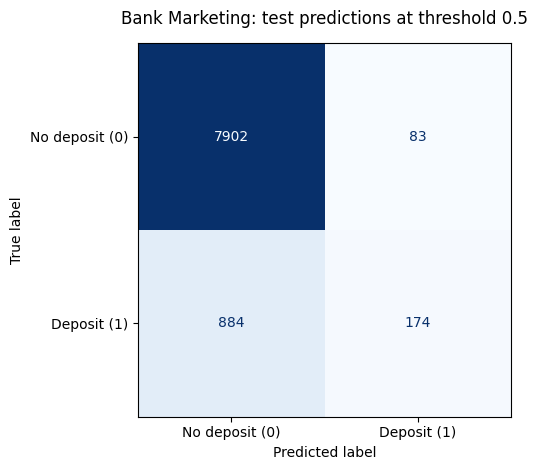

In [10]:
test_confusion_matrix = confusion_matrix(y_test, test_decisions, labels=[0, 1])
positive_recall = test_confusion_matrix[1, 1] / test_confusion_matrix[1].sum()
print(f'Found positive clients: {test_confusion_matrix[1, 1]} of {test_confusion_matrix[1].sum()}')
print(f'Recall of deposit class: {positive_recall:.2%}')

fig, ax = plt.subplots(figsize=(6.2, 4.8))
ConfusionMatrixDisplay(
    test_confusion_matrix, display_labels=['No deposit (0)', 'Deposit (1)']
).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
ax.set_title('Bank Marketing: test predictions at threshold 0.5', pad=14)
fig.tight_layout()
Path('images').mkdir(exist_ok=True)
fig.savefig('images/test_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

Модель правильно определяет большинство отказов, но пропускает много согласий.
Поэтому accuracy около 89,3% не означает, что модель находит 89,3% согласившихся.
Польза для реальной кампании также зависит от стоимости контакта и ценности
оформленного депозита; в этом эксперименте они не заданы.

## 11. Прогноз для одного клиента

Берём одну строку исходных признаков через `iloc[[0]]`: двойные скобки сохраняют
двумерную таблицу. Применяем уже обученные итоговые преобразования.
Ни `fit`, ни `fit_transform` для нового клиента не нужны.

In [11]:
client = df_test.iloc[[0]]
actual = int(y_test.iloc[0])
display(client)

client_encoded = dv_final.transform(client.to_dict(orient='records'))
client_scaled = client_encoded.copy()
client_scaled[:, numerical_mask_final] = scaler_final.transform(
    client_encoded[:, numerical_mask_final]
)
client_probability = float(model_final.predict_proba(client_scaled)[0, 1])
client_decision = int(client_probability >= THRESHOLD)

assert np.isclose(client_probability, test_probabilities[0])
display(pd.DataFrame([{
    'probability_of_deposit': client_probability,
    'decision_at_0.5': client_decision,
    'actual': actual,
}]).round(6))

,job,education,housing,loan,poutcome,age,balance,previous
1392,blue-collar,primary,yes,yes,unknown,40,640,0


,probability_of_deposit,decision_at_0.5,actual
0,0.02992,0,0


Вероятность — численная оценка модели; решение — результат применения порога;
фактический ответ — наблюдённый исход из данных. Для выбранного клиента вероятность
около 3%, поэтому решение равно `0`; фактический ответ также равен `0`.
Совпадение одного решения с фактом не заменяет оценку по всей выборке.

## 12. Выводы и ограничения

- На test логистическая регрессия получает accuracy **89,31%** против **88,30%** у baseline;
  log loss — **0,316915** против **0,360898**. Это улучшение относительно постоянного прогноза
  на данном разбиении, без вывода о статистической значимости.
- При пороге `0.5` найдено **174 из 1 058** согласившихся: recall около **16,45%**.
  Одной accuracy для описания поведения модели недостаточно.
- Подготовка признаков обучается на той же обучающей части, что и модель.
  Для validation, test и отдельного клиента применяются сохранённые правила.
- Случайное стратифицированное разбиение — учебное упрощение. UCI указывает,
  что `bank-full.csv` упорядочен по времени; эта оценка не доказывает качество
  прогнозирования будущих кампаний. В данных могут присутствовать повторные контакты,
  а идентификатора клиента для групповой проверки здесь нет.
- Использовано восемь заранее выбранных признаков и одна модель. Подбор параметров,
  сравнение алгоритмов и выбор порога по экономическим условиям в задачу не входили.

Работа выполнена при изучении Machine Learning Zoomcamp. ChatGPT использовался для
постановки учебной задачи, объяснений, проверки кода и подготовки репозитория к публикации.

### Источники

- [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing):
  Moro, S., Rita, P., & Cortez, P. (2014). Bank Marketing [Dataset].
  [DOI: 10.24432/C5K306](https://doi.org/10.24432/C5K306).
- Данные: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
- [Machine Learning Zoomcamp](https://github.com/DataTalksClub/machine-learning-zoomcamp).
- Документация scikit-learn: [DictVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.DictVectorizer.html),
  [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html),
  [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html),
  [accuracy_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html),
  [log_loss](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.log_loss.html).